# Misinformation diffusion

A guided exploration of the shared SI model and reproducible reference results.
See [methodology](../docs/methodology.md) for assumptions. Select the project Python kernel. This notebook does not rerun or overwrite the full reference experiment.

In [1]:
from pathlib import Path
import sys
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / 'pyproject.toml').exists():
    ROOT = ROOT.parent
if not (ROOT / 'pyproject.toml').exists():
    raise RuntimeError('Run from the repository root or notebooks directory')
sys.path.insert(0, str(ROOT))
from simulations.network import build_er_network, build_ba_network
from simulations.run_diffusion import simulate_diffusion
from simulations.utils import sweep_probabilities
from analysis.fit_logistic import logistic, fit_logistic
from analysis.compute_metrics import empirical_threshold

## 1. Inspect a seeded network

A small example is useful for exploring the process; it is not the reference experiment.

In [2]:
G = build_er_network(n=100, p_edge=8/99, seed=42)
print(f'Nodes: {len(G)} · Edges: {G.number_of_edges()} · Clustering: {nx.average_clustering(G):.3f}')
print('Adoption at p=0:', simulate_diffusion(G, 0, seed=42))
print('Adoption at p=1:', simulate_diffusion(G, 1, seed=42))
assert simulate_diffusion(G, 0, seed=42) == 1/100

Nodes: 100 · Edges: 377 · Clustering: 0.065
Adoption at p=0: 0.01
Adoption at p=1: 1.0


## 2. Run a small sweep

This example reuses the CLI model and fixed seeds. Only ten trials on a single graph are used here; these values do not estimate graph-to-graph uncertainty.

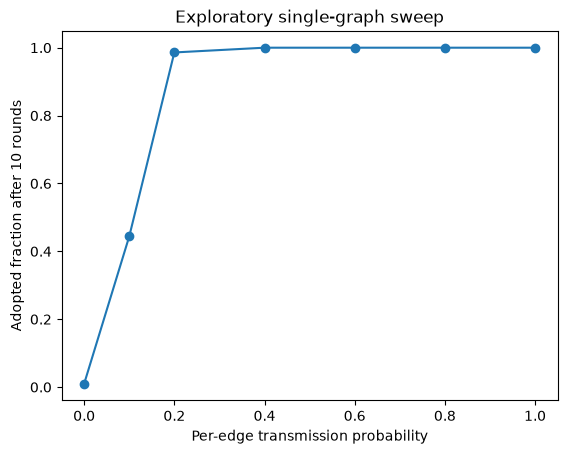

In [3]:
curve = sweep_probabilities(G, [0, .1, .2, .4, .6, .8, 1], runs=10, seed=42)
plt.plot(list(curve), list(curve.values()), marker='o')
plt.xlabel('Per-edge transmission probability')
plt.ylabel('Adopted fraction after 10 rounds')
plt.title('Exploratory single-graph sweep')
plt.show()

## 3. Read the reference experiment

The reference results average independent graph replicates. The fitted 50% midpoint and first tested probability reaching 80% are distinct summaries. Empty values mean a threshold or supported fit was not available.

In [4]:
summary = pd.read_csv(ROOT / 'results/csv/summary.csv')
summary[['network', 'threshold_80', 'logistic_midpoint', 'mean_clustering', 'fit_status']]

,network,threshold_80,logistic_midpoint,mean_clustering,fit_status
0,ER,0.20,0.139019,0.010341,fitted
1,BA,0.20,0.110972,0.041498,fitted
2,WS β=0,NaN,NaN,0.642857,Sampled curve does not bracket 50% adoption; m...
3,WS β=0.01,NaN,NaN,0.626153,Sampled curve does not bracket 50% adoption; m...
4,WS β=0.1,0.35,0.242392,0.473293,fitted
5,WS β=0.5,0.20,0.146912,0.087431,fitted
6,WS β=1,0.20,0.141489,0.009188,fitted


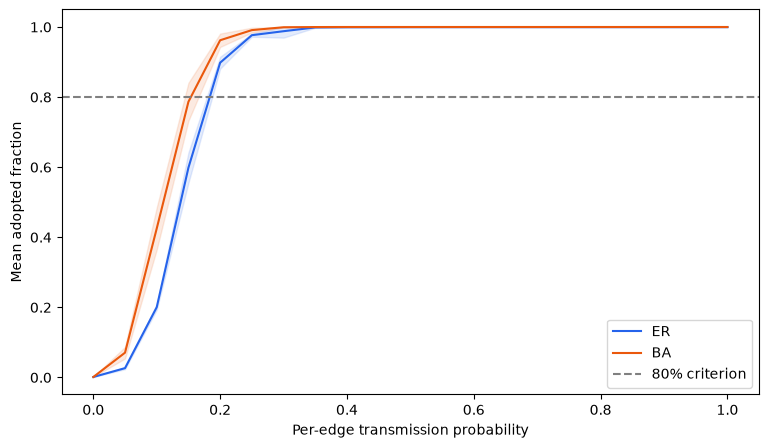

In [5]:
curves = pd.read_csv(ROOT / 'results/csv/adoption_curves.csv')
fig, ax = plt.subplots(figsize=(9, 5))
for name, color in [('ER', '#2563eb'), ('BA', '#ea580c')]:
    c = curves[curves.network == name]
    ax.plot(c.p, c['mean'], label=name, color=color)
    ax.fill_between(c.p, c.ci_low, c.ci_high, color=color, alpha=.12)
ax.axhline(.8, linestyle='--', color='gray', label='80% criterion')
ax.set(xlabel='Per-edge transmission probability', ylabel='Mean adopted fraction')
ax.legend()
plt.show()

## 4. Interpret carefully

The shaded bands describe uncertainty in graph-level mean adoption, not individual cascade ranges. ER and BA have the same sampled 80% threshold in this run despite different fitted midpoints. WS rewiring changes clustering and path lengths together, so its comparison does not isolate clustering causally. Synthetic SI results are not predictions of real-world misinformation.

For new experiments, run `misinformation-study --help` and use a separate output directory. All trial seeds and experiment parameters are saved by the CLI.